# 00 — ASTs não lineares estáveis por contração

## Resumo

Este experimento implementa e testa um gerador de recorrências AST não lineares certificado em um domínio limitado. Os lags são reunidos no estado aumentado $s_t=(x_t,x_{t-1},\ldots,x_{t-L+1})$. A árvore sorteada é escalada até que um limite intervalar satisfaça $\sup_{s\in D}\|J_F(s)\|_{w,\infty}<1$ e até que o domínio permaneça invariante sob uma inovação uniforme limitada. O certificado verifica domínio, derivadas, deslocamento dos lags, singularidades e ruído antes da geração. Simulações Monte Carlo procuram violações do domínio e do limite da Jacobiana como validação complementar, sem substituir a garantia analítica.

## 1. Estado aumentado e norma ponderada

Para $x_{t+1}=f(x_t,\ldots,x_{t-L+1})+\varepsilon_{t+1}$, definimos

$$F(s_t,\varepsilon_{t+1})=(f(s_t)+\varepsilon_{t+1},x_t,\ldots,x_{t-L+2}).$$

Na norma infinita usual, as linhas que deslocam os lags têm ganho exatamente um. Usamos $\|s\|_{w,\infty}=\max_i |s_i|/w_i$ com $w_i=q^i$ e $q>1$. O ganho do deslocamento passa a ser $1/q<1$, enquanto a primeira linha é limitada por $\sum_j |\partial f/\partial s_j|q^j$. A propagação intervalar em $D=[-R,R]^L$ fornece limites uniformes para essas derivadas. Também exigimos $\sup_{s\in D}|f(s)|+b\le R$, onde $|\varepsilon_t|\le b$.

In [1]:
from __future__ import annotations

from dataclasses import asdict
from pathlib import Path
import importlib.metadata
import json
import platform
import subprocess
import sys
import time

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'src' / 'tsfmxai').exists():
            return candidate
    raise RuntimeError('Repository root not found.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_ROOT = PROJECT_ROOT / 'src'
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from tsfmxai.generators import (
    ContractionTreeConfig,
    RandomTreeConfig,
    sample_contractive_mechanisms,
    sample_contractive_trajectories,
    validate_contraction_monte_carlo,
)

ROOT_SEED = 20261006
MECHANISM_COUNT = 1_000
VALIDATED_MECHANISMS = 200
TRAJECTORIES_PER_VALIDATION = 8
GENERATED_STEPS = 384
REFERENCE_INNOVATION_STD = 0.05
INNOVATION_BOUND = np.sqrt(3.0) * REFERENCE_INNOVATION_STD

TREE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=0.55,
    time_probability=0.0, lag_probability=0.45, add_probability=0.80,
    minimum_parameter_magnitude=0.05, maximum_parameter_magnitude=0.80,
    require_lag=True, require_time=False, coefficient_gate_lags=True,
)
CONTRACTION_CONFIG = ContractionTreeConfig(
    tree_config=TREE_CONFIG, domain_radius=1.0,
    innovation_bound=INNOVATION_BOUND, lag_weight_growth=1.25,
    target_lipschitz=0.90, scale_safety_factor=0.95,
)
configuration = {
    'root_seed': ROOT_SEED, 'mechanism_count': MECHANISM_COUNT,
    'validated_mechanisms': VALIDATED_MECHANISMS,
    'trajectories_per_validation': TRAJECTORIES_PER_VALIDATION,
    'generated_steps': GENERATED_STEPS,
    'reference_innovation_std': REFERENCE_INNOVATION_STD,
    'contraction_config': {
        **asdict(CONTRACTION_CONFIG),
        'tree_config': asdict(TREE_CONFIG),
    },
}
print(json.dumps(configuration, indent=2))

{
  "root_seed": 20261006,
  "mechanism_count": 1000,
  "validated_mechanisms": 200,
  "trajectories_per_validation": 8,
  "generated_steps": 384,
  "reference_innovation_std": 0.05,
  "contraction_config": {
    "tree_config": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnitude": 0.8,
      "require_lag": true,
      "require_time": false,
      "coefficient_gate_lags": true
    },
    "domain_radius": 1.0,
    "innovation_bound": 0.08660254037844387,
    "lag_weight_growth": 1.25,
    "target_lipschitz": 0.9,
    "scale_safety_factor": 0.95,
    "minimum_scale": 1e-10
  }
}


**O que foi feito.** Foram fixados domínio $[-1,1]^L$, pesos $1.25^i$ e alvo de Lipschitz 0,90. A inovação uniforme tem limite $\sqrt{3}\,0.05$, escolhida para possuir desvio-padrão 0,05 e, simultaneamente, suporte limitado. Terminais de tempo são excluídos porque impediriam a invariância de uma caixa fixa.

## 2. Amostragem e certificação

Cada AST-base preserva somas, produtos e lags sorteados. Um fator externo positivo é calculado a partir do menor limite necessário para satisfazer simultaneamente a contração e a invariância do domínio.

In [2]:
sampling_started = time.perf_counter()
mechanisms = sample_contractive_mechanisms(
    CONTRACTION_CONFIG, root_seed=ROOT_SEED, count=MECHANISM_COUNT
)
sampling_seconds = time.perf_counter() - sampling_started
assert all(mechanism.certificate.holds for mechanism in mechanisms)

examples = pd.DataFrame([
    {
        'sample_index': mechanism.sample_index,
        'formula': mechanism.formula,
        'scale': mechanism.scale,
        'state_dimension': mechanism.certificate.state_dimension,
        'Lipschitz_upper_bound': mechanism.certificate.lipschitz_upper_bound,
        'domain_margin': mechanism.certificate.domain_margin,
    }
    for mechanism in mechanisms[:5]
])
display(examples)
print(f'{MECHANISM_COUNT / sampling_seconds:,.1f} certified mechanisms / second')

,sample_index,formula,scale,state_dimension,Lipschitz_upper_bound,domain_margin
0,0,x_0(t) = (0.1456 * ((0.547543 + (0.30544 * x_0...,0.145600,11,0.855000,0.657029
1,1,x_0(t) = (0.95 * ((-0.299221 * x_0(t-4)) + -0....,0.950000,4,0.800000,0.397445
2,2,x_0(t) = (0.584982 * (((0.508927 + (-0.481554 ...,0.584982,10,0.850075,0.045670
3,3,x_0(t) = (0.628345 * (((0.142897 + (0.328209 *...,0.628345,4,0.800000,0.045670
4,4,x_0(t) = (0.188994 * ((0.378753 * x_0(t-6)) + ...,0.188994,8,0.855000,0.395926


1,259.1 certified mechanisms / second


**O que foi feito.** Mil estruturas foram sorteadas, escaladas e certificadas antes de qualquer série ser gerada. Os exemplos retêm a fórmula executável, a escala aplicada e as duas margens do certificado.

In [3]:
certificate_rows = pd.DataFrame([
    {
        'sample_index': mechanism.sample_index,
        'state_dimension': mechanism.certificate.state_dimension,
        'scale': mechanism.scale,
        'top_row_gain': mechanism.certificate.top_row_gain_bound,
        'shift_gain': mechanism.certificate.shift_gain,
        'Lipschitz_upper_bound': mechanism.certificate.lipschitz_upper_bound,
        'contraction_margin': mechanism.certificate.contraction_margin,
        'deterministic_output_bound': mechanism.certificate.deterministic_output_bound,
        'noisy_output_bound': mechanism.certificate.noisy_output_bound,
        'domain_margin': mechanism.certificate.domain_margin,
        'singularity_free': mechanism.certificate.singularity_free,
    }
    for mechanism in mechanisms
])
certificate_summary = certificate_rows.describe().T
display(certificate_summary)
display(certificate_rows.groupby('state_dimension').agg(
    mechanisms=('sample_index', 'size'),
    maximum_Lipschitz=('Lipschitz_upper_bound', 'max'),
    minimum_domain_margin=('domain_margin', 'min'),
).reset_index())
assert certificate_rows['Lipschitz_upper_bound'].max() < 1.0
assert certificate_rows['domain_margin'].min() >= -1e-12
assert certificate_rows['singularity_free'].all()

,count,mean,std,min,25%,50%,75%,max
sample_index,1000.0,499.500000,288.819436,0.000000,249.750000,499.500000,749.250000,999.000000
state_dimension,1000.0,8.298000,3.101099,1.000000,6.000000,9.000000,11.000000,12.000000
scale,1000.0,0.468354,0.322339,0.045672,0.172276,0.366321,0.814703,0.950000
top_row_gain,1000.0,0.733978,0.232685,0.003473,0.742115,0.855000,0.855000,0.855000
shift_gain,1000.0,0.780800,0.122500,0.000000,0.800000,0.800000,0.800000,0.800000
Lipschitz_upper_bound,1000.0,0.827696,0.092526,0.022415,0.800000,0.855000,0.855000,0.855000
contraction_margin,1000.0,0.172304,0.092526,0.145000,0.145000,0.145000,0.200000,0.977585
deterministic_output_bound,1000.0,0.361894,0.251810,0.003678,0.161268,0.283500,0.525474,0.867728
noisy_output_bound,1000.0,0.448497,0.251810,0.090280,0.247870,0.370103,0.612077,0.954330
domain_margin,1000.0,0.551503,0.251810,0.045670,0.387923,0.629897,0.752130,0.909720


,state_dimension,mechanisms,maximum_Lipschitz,minimum_domain_margin
0,1,24,0.753331,0.045670
1,2,31,0.855000,0.045670
2,3,42,0.855000,0.045670
3,4,55,0.855000,0.045670
4,5,59,0.855000,0.045670
5,6,63,0.855000,0.045670
6,7,84,0.855000,0.045670
7,8,85,0.855000,0.107129
8,9,126,0.855000,0.045670
9,10,126,0.855000,0.045670


**O que foi feito.** Os componentes do certificado foram agregados globalmente e por dimensão do estado. A checagem de singularidades é direta nesta gramática porque somente soma e multiplicação são admitidas; operadores futuros, como divisão ou logaritmo, precisarão provar seus próprios domínios válidos.

## 3. O que o certificado verifica

In [4]:
checks = pd.DataFrame([
    {'check': 'domain', 'rule': 'all lag coordinates lie in [-R, R]',
     'failure_action': 'reject configuration or rescale the AST'},
    {'check': 'singularities', 'rule': 'all interval and derivative bounds are finite',
     'failure_action': 'reject the expression'},
    {'check': 'noise', 'rule': '|epsilon| <= b and sup|f| + b <= R',
     'failure_action': 'reject unbounded noise for a hard domain guarantee'},
    {'check': 'Jacobian', 'rule': 'weighted top-row gain and lag-shift gain are < 1',
     'failure_action': 'reduce the external scale or change the weights'},
    {'check': 'Monte Carlo', 'rule': 'sampled paths respect domain and local bound',
     'failure_action': 'treat any violation as an implementation error'},
])
display(checks)

,check,rule,failure_action
0,domain,"all lag coordinates lie in [-R, R]",reject configuration or rescale the AST
1,singularities,all interval and derivative bounds are finite,reject the expression
2,noise,|epsilon| <= b and sup|f| + b <= R,reject unbounded noise for a hard domain guara...
3,Jacobian,weighted top-row gain and lag-shift gain are < 1,reduce the external scale or change the weights
4,Monte Carlo,sampled paths respect domain and local bound,treat any violation as an implementation error


**O que foi feito.** A tabela separa as condições matemáticas das checagens empíricas. A simulação não cria a garantia: ela procura erros de implementação ou hipóteses registradas incorretamente.

## 4. Validação Monte Carlo

In [5]:
validation_started = time.perf_counter()
reports = [
    validate_contraction_monte_carlo(
        mechanism, trajectory_count=TRAJECTORIES_PER_VALIDATION,
        generated_steps=GENERATED_STEPS,
        root_seed=ROOT_SEED + 10_000 + int(mechanism.sample_index),
    )
    for mechanism in mechanisms[:VALIDATED_MECHANISMS]
]
validation_seconds = time.perf_counter() - validation_started
validation_summary = pd.Series({
    'validated_mechanisms': len(reports),
    'trajectories': sum(report.trajectory_count for report in reports),
    'evaluated_state_transitions': sum(
        report.evaluated_state_transitions for report in reports
    ),
    'domain_violations': sum(report.domain_violations for report in reports),
    'certificate_violations': sum(
        report.certificate_violations for report in reports
    ),
    'maximum_observed_absolute_value': max(
        report.maximum_observed_absolute_value for report in reports
    ),
    'maximum_observed_local_Lipschitz': max(
        report.maximum_observed_local_lipschitz for report in reports
    ),
    'validation_seconds': validation_seconds,
}, name='value').to_frame()
display(validation_summary)
assert all(report.passed for report in reports)

,value
validated_mechanisms,200.000000
trajectories,1600.000000
evaluated_state_transitions,614400.000000
domain_violations,0.000000
certificate_violations,0.000000
maximum_observed_absolute_value,0.999761
maximum_observed_local_Lipschitz,0.855000
validation_seconds,79.531419


**O que foi feito.** Duzentos mecanismos foram estressados com oito trajetórias de 384 passos cada. Em todos os estados visitados, calculamos a Jacobiana local exata na norma ponderada e comparamos com o limite intervalar certificado.

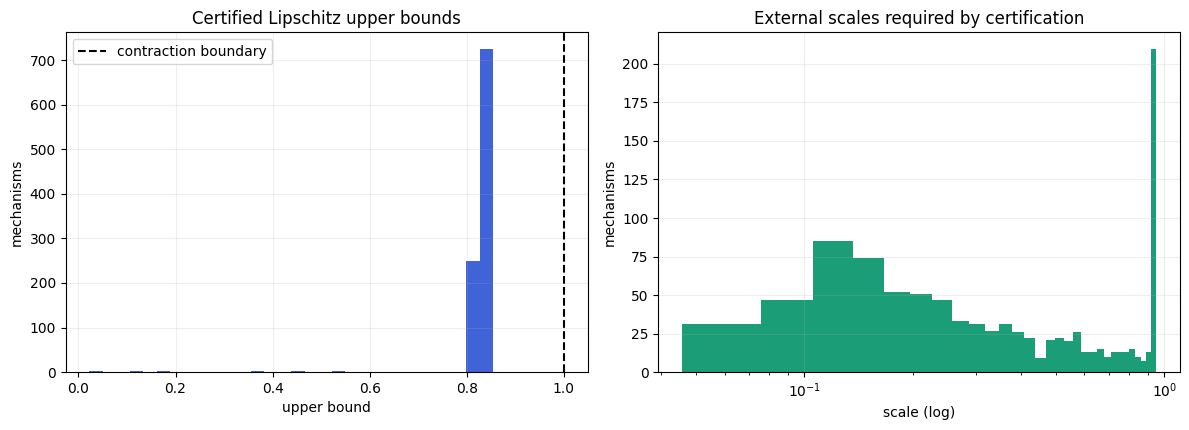

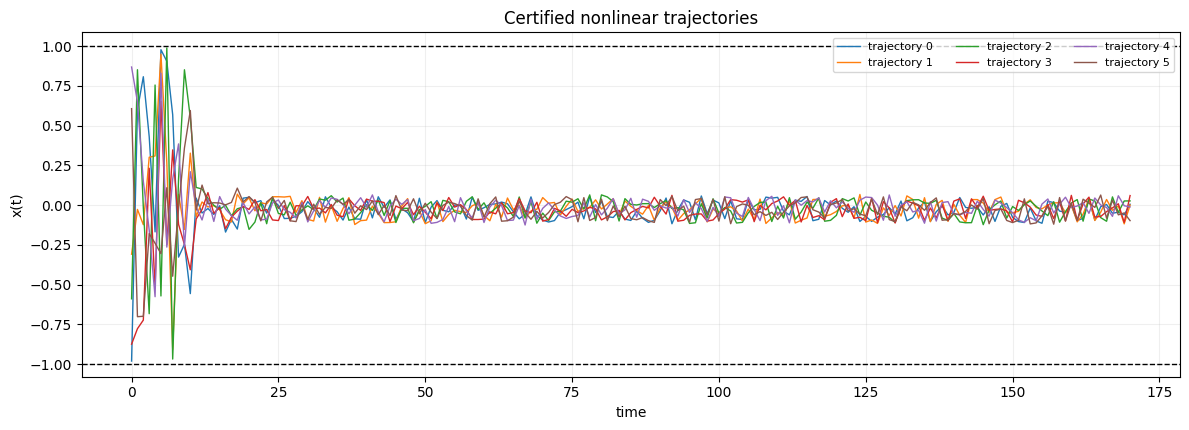

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].hist(certificate_rows['Lipschitz_upper_bound'], bins=30, color='#4063d8')
axes[0].axvline(1.0, color='black', linestyle='--', label='contraction boundary')
axes[0].set(title='Certified Lipschitz upper bounds', xlabel='upper bound', ylabel='mechanisms')
axes[0].legend()
axes[1].hist(certificate_rows['scale'], bins=30, color='#1b9e77')
axes[1].set_xscale('log')
axes[1].set(title='External scales required by certification',
            xlabel='scale (log)', ylabel='mechanisms')
for axis in axes:
    axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

display_mechanism = mechanisms[0]
display_trajectories = sample_contractive_trajectories(
    display_mechanism, trajectory_count=6, generated_steps=160,
    root_seed=ROOT_SEED + 99_000,
)
fig, ax = plt.subplots(figsize=(12, 4.4))
for index, trajectory in enumerate(display_trajectories):
    ax.plot(trajectory, linewidth=1.0, label=f'trajectory {index}')
radius = display_mechanism.certificate.domain_radius
ax.axhline(radius, color='black', linestyle='--', linewidth=1)
ax.axhline(-radius, color='black', linestyle='--', linewidth=1)
ax.set(title='Certified nonlinear trajectories', xlabel='time', ylabel='x(t)')
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**O que foi feito.** Os histogramas mostram a folga dos certificados e quanto cada AST precisou ser reduzida. As trajetórias ilustrativas incluem todo o histórico inicial e permanecem dentro das fronteiras certificadas do domínio.

## 5. Interpretação

O certificado prova contração de duas trajetórias submetidas à mesma sequência de inovações e invariância de $D$ para a lei de ruído limitada declarada. Isso fornece estabilidade incremental e impede explosões fora da caixa. A garantia é local ao domínio, conservadora por usar intervalos e dependente da norma ponderada. Ela não se aplica automaticamente a ruído gaussiano, a estados iniciais fora de $D$ ou a novos operadores sem regras de domínio e derivada. Escalas muito pequenas também podem gerar mecanismos pouco informativos; por isso sua distribuição deve permanecer uma métrica do benchmark.

## Registro completo do experimento

In [7]:
def git_output(*arguments: str) -> str | None:
    try:
        return subprocess.check_output(
            ['git', *arguments], cwd=PROJECT_ROOT, text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


experiment_record = {
    'experiment_id': 'abstract_syntax_tree_contraction_000_certificate_monte_carlo',
    'status': 'executed',
    'research_question': (
        'Can nonlinear lagged ASTs be scaled to satisfy a rigorous bounded-domain '
        'contraction certificate and retain that behavior under Monte Carlo stress tests?'
    ),
    'configuration': configuration,
    'seed_policy': {
        'mechanism_seed': 'derive_sample_seed(ROOT_SEED, sample_index)',
        'validation_seed': 'ROOT_SEED + 10000 + sample_index',
        'external_global_rng_used': False,
    },
    'provenance': {
        'implementation': [
            'src/tsfmxai/generators/contraction.py',
            'src/tsfmxai/generators/random_expression.py',
            'src/tsfmxai/generators/trajectory.py',
        ],
        'project_head': git_output('rev-parse', 'HEAD'),
        'python': sys.version, 'platform': platform.platform(),
        'packages': {name: importlib.metadata.version(name)
                     for name in ['numpy', 'pandas', 'matplotlib']},
    },
    'metrics': {
        'sampling_seconds': sampling_seconds,
        'certified_mechanisms_per_second': MECHANISM_COUNT / sampling_seconds,
        'certificate_summary': json.loads(certificate_summary.to_json()),
        'validation_summary': validation_summary['value'].to_dict(),
    },
    'scientific_summary': (
        f'{MECHANISM_COUNT} of {MECHANISM_COUNT} sampled mechanisms satisfied the analytic '
        f'contraction and invariant-domain certificate. Monte Carlo evaluated '
        f"{int(validation_summary.loc['evaluated_state_transitions', 'value'])} state transitions "
        f"with {int(validation_summary.loc['domain_violations', 'value'])} domain violations and "
        f"{int(validation_summary.loc['certificate_violations', 'value'])} Jacobian-bound violations."
    ),
    'limitations': [
        'The certificate is restricted to a declared bounded domain.',
        'Hard domain invariance requires the declared bounded innovation law.',
        'Interval derivative bounds can be conservative and force small external scales.',
        'The current implementation is univariate and supports Add and Multiply AST operators.',
        'Monte Carlo validation detects implementation failures but does not replace the proof.',
    ],
    'reproduction_command': (
        r'.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace '
        r'experiments\abstract_syntax_tree\contraction_by_construction\00_contraction_certificate_and_monte_carlo.ipynb '
        r'--ExecutePreprocessor.timeout=2400'
    ),
}
print(json.dumps(experiment_record, indent=2, ensure_ascii=False))

{
  "experiment_id": "abstract_syntax_tree_contraction_000_certificate_monte_carlo",
  "status": "executed",
  "research_question": "Can nonlinear lagged ASTs be scaled to satisfy a rigorous bounded-domain contraction certificate and retain that behavior under Monte Carlo stress tests?",
  "configuration": {
    "root_seed": 20261006,
    "mechanism_count": 1000,
    "validated_mechanisms": 200,
    "trajectories_per_validation": 8,
    "generated_steps": 384,
    "reference_innovation_std": 0.05,
    "contraction_config": {
      "tree_config": {
        "minimum_operators": 1,
        "maximum_operators": 6,
        "num_series": 1,
        "minimum_lag": 1,
        "maximum_lag": 12,
        "parameter_probability": 0.55,
        "time_probability": 0.0,
        "lag_probability": 0.45,
        "add_probability": 0.8,
        "minimum_parameter_magnitude": 0.05,
        "maximum_parameter_magnitude": 0.8,
        "require_lag": true,
        "require_time": false,
        "coefficie

**O que foi feito.** A célula registra configuração, sementes, proveniência, métricas, limitações e comando de reprodução no próprio notebook executado.